# The Retro Canon: 205 Games, 41 Systems

**What this notebook is.** `TOP5_GAMES.md` is a curated list — 5 "most unique" games
for each of the 41 systems in this collection. A list is an assertion. This notebook
is the audit: it takes the curation as *data*, joins it to hardware facts nobody
curated (install base, launch year, library size, media format), and asks what the
numbers actually support.

**The honest framing.** The dependent variable, `canon_score`, is an **editorial
index** written by the same hand that picked the games. So the question is never
"is this game good" — it is:

> Does a hand-built canon line up with independent, uncurated evidence —
> and where it doesn't, is that a flaw in the curation or a real property of
> retro gaming?

**Five questions this notebook answers with tests, not vibes**

| # | Question | Method |
|---|----------|--------|
| 1 | Do a platform's best games arrive *late* in its life? | per-system lag distribution, Kruskal–Wallis across categories, permutation test |
| 2 | Does hardware success buy a better library? | OLS of mean canon on log install base + residual ranking |
| 3 | Is the curation biased toward games that sold? | Spearman on the observed subset + MNAR missingness test |
| 4 | Who actually built the canon? | developer concentration, Gini / HHI |
| 5 | Are there natural *archetypes* of retro platform? | PCA + k-means on hardware features |

**Design note.** Every chart in here follows one visual system: a validated
8-slot categorical palette assigned in fixed order (never cycled), a single
one-hue sequential ramp for magnitude, a blue↔red diverging pair with a neutral
grey midpoint for signed residuals, thin marks, recessive axes, a legend whenever
there are ≥2 series, and **never a second y-axis**. Scatter/bubble forms are
capped at 3 series because only the first three slots clear colour-blind
separation on an all-pairs basis.

## 1 · Setup, palette, and loading the data

In [1]:
import os, json, math, itertools, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 40)
RNG = np.random.default_rng(20261112)   # fixed seed: every number below is reproducible

# ---------------------------------------------------------------- palette ---
# Validated 8-slot categorical palette, assigned in FIXED order, never cycled.
MODE = "light"                                    # flip to "dark" and re-run
PAL = {
    "light": dict(
        surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", ink3="#8a8a85",
        grid="#e8e7e3", mid="#f0efec",
        cat=["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#4a3aa7","#e34948"],
        seq=["#cde2fb","#b7d3f6","#9ec5f4","#86b6ef","#6da7ec","#5598e7","#3987e5",
             "#2a78d6","#256abf","#1c5cab","#184f95","#104281","#0d366b"],
    ),
    "dark": dict(
        surface="#1a1a19", ink="#ffffff", ink2="#c3c2b7", ink3="#8a8a85",
        grid="#2e2e2c", mid="#383835",
        cat=["#3987e5","#d95926","#199e70","#c98500","#d55181","#008300","#9085e9","#e66767"],
        seq=["#0d366b","#104281","#184f95","#1c5cab","#256abf","#2a78d6","#3987e5",
             "#5598e7","#6da7ec","#86b6ef","#9ec5f4","#b7d3f6","#cde2fb"],
    ),
}[MODE]
CAT, SEQ = PAL["cat"], PAL["seq"]
DIVERGE = (CAT[0], PAL["mid"], CAT[7])            # blue <-> grey <-> red

mpl.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"],
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink2"],
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"],
    "axes.edgecolor": PAL["grid"], "grid.color": PAL["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 14,
    "figure.dpi": 120, "lines.linewidth": 2, "lines.markersize": 8,
    "legend.frameon": False, "legend.fontsize": 9.5,
})

def frame(ax, title=None, sub=None, xlabel=None, ylabel=None, axis="y"):
    # recessive grid on one axis, left-aligned title, optional deck subtitle
    if title:
        ax.text(0, 1.085 if sub else 1.03, title, transform=ax.transAxes,
                fontsize=12.5, fontweight="bold", color=PAL["ink"], va="bottom")
    if sub:
        ax.text(0, 1.022, sub, transform=ax.transAxes, fontsize=9.5,
                color=PAL["ink3"], va="bottom")
    ax.grid(True, axis=axis, alpha=0.9, zorder=0)
    ax.set_axisbelow(True)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax

print(f"palette mode: {MODE} · {len(CAT)} categorical slots · seed locked")

palette mode: light · 8 categorical slots · seed locked


In [2]:
# ------------------------------------------------------------------ load ---
ROOT = os.path.abspath(os.path.join(os.getcwd()))
if not os.path.isdir(os.path.join(ROOT, "data")):      # notebook run from elsewhere
    ROOT = os.path.dirname(ROOT)
DATA = os.path.join(ROOT, "data")

systems = pd.read_csv(os.path.join(DATA, "systems.csv"))
games   = pd.read_csv(os.path.join(DATA, "games.csv"))
tools   = pd.read_csv(os.path.join(DATA, "tools.csv"))

df = games.merge(systems, left_on="sys_id", right_on="id", how="left",
                 validate="many_to_one")

# derived features
df["lag"]        = df["year"] - df["launch"]            # years after platform launch
df["decade"]     = (df["year"] // 10) * 10
df["has_sales"]  = df["sales_m"].notna()
df["log_sales"]  = np.log10(df["sales_m"])
df["is_excl"]    = df["exclusive"].isin(["exclusive", "regional", "arcade-only"])
systems["log_units"] = np.log10(systems["units_m"].replace(0, np.nan))
systems["lib"]   = systems["library_size"].str.lstrip("~").astype(int)

print(f"{len(systems)} systems · {len(games)} games · {df.shape[1]} columns after join")
assert len(df) == 205 and df["sys_id"].nunique() == 41
assert (df.groupby("sys_id").size() == 5).all(), "not exactly 5 picks per system"
df.head(3)

41 systems · 205 games · 26 columns after join


,sys_id,rank,game,year,genre,developer,exclusive,sales_m,canon_score,note_x,id,system,maker,category,launch,gen,units_m,media,cpu_bits,library_size,note_y,lag,decade,has_sales,log_sales,is_excl
0,nes,1,Super Mario Bros. 3,1988,Platformer,Nintendo R&D4,exclusive,17.28,99,"The 8-bit platformer's final form: world map, ...",nes,NES,Nintendo,Console,1983,3,61.91,Cartridge,8,~1400,Western branding of the Famicom (US 1985); 61....,5,1980,True,1.237544,True
1,nes,2,The Legend of Zelda,1986,Action-adventure,Nintendo R&D4,exclusive,6.51,98,Battery-backed saves invented the long-form co...,nes,NES,Nintendo,Console,1983,3,61.91,Cartridge,8,~1400,Western branding of the Famicom (US 1985); 61....,3,1980,True,0.813581,True
2,nes,3,Mega Man 2,1988,Action-platformer,Capcom,exclusive,1.50,94,Non-linear stage select plus the best NES soun...,nes,NES,Nintendo,Console,1983,3,61.91,Cartridge,8,~1400,Western branding of the Famicom (US 1985); 61....,5,1980,True,0.176091,True


## 2 · Data integrity and shape

Before any inference: what is actually in here, and what is missing. The
missingness is not noise — it is the first finding.

In [3]:
overview = pd.DataFrame({
    "non-null": df.notna().sum(),
    "null": df.isna().sum(),
    "dtype": df.dtypes.astype(str),
})
overview["null %"] = (100 * overview["null"] / len(df)).round(1)
display(overview.loc[["game","year","genre","developer","exclusive","sales_m",
                      "canon_score","units_m","lag"]])

print("\n--- canon_score ---")
print(df["canon_score"].describe().round(2).to_string())
print(f"\nskew {stats.skew(df.canon_score):+.2f} · kurtosis {stats.kurtosis(df.canon_score):+.2f}")
print(f"Shapiro-Wilk p = {stats.shapiro(df.canon_score).pvalue:.4g}"
      "  -> left-skewed, NOT normal; use rank-based tests throughout")

print("\n--- coverage ---")
print(f"software sales figures published for {df.has_sales.sum()}/{len(df)} "
      f"({100*df.has_sales.mean():.0f}%) of picks")
print(f"hardware install base known for {systems.units_m.notna().sum()}/{len(systems)} systems "
      "(arcade boards have none by definition)")

,non-null,null,dtype,null %
game,205,0,str,0.0
year,205,0,int64,0.0
genre,205,0,str,0.0
developer,205,0,str,0.0
exclusive,205,0,str,0.0
sales_m,46,159,float64,77.6
canon_score,205,0,int64,0.0
units_m,180,25,float64,12.2
lag,205,0,int64,0.0



--- canon_score ---
count    205.00
mean      86.79
std        9.27
min       50.00
25%       82.00
50%       88.00
75%       94.00
max      100.00

skew -1.10 · kurtosis +1.18
Shapiro-Wilk p = 4.682e-09  -> left-skewed, NOT normal; use rank-based tests throughout

--- coverage ---
software sales figures published for 46/205 (22%) of picks
hardware install base known for 36/41 systems (arcade boards have none by definition)


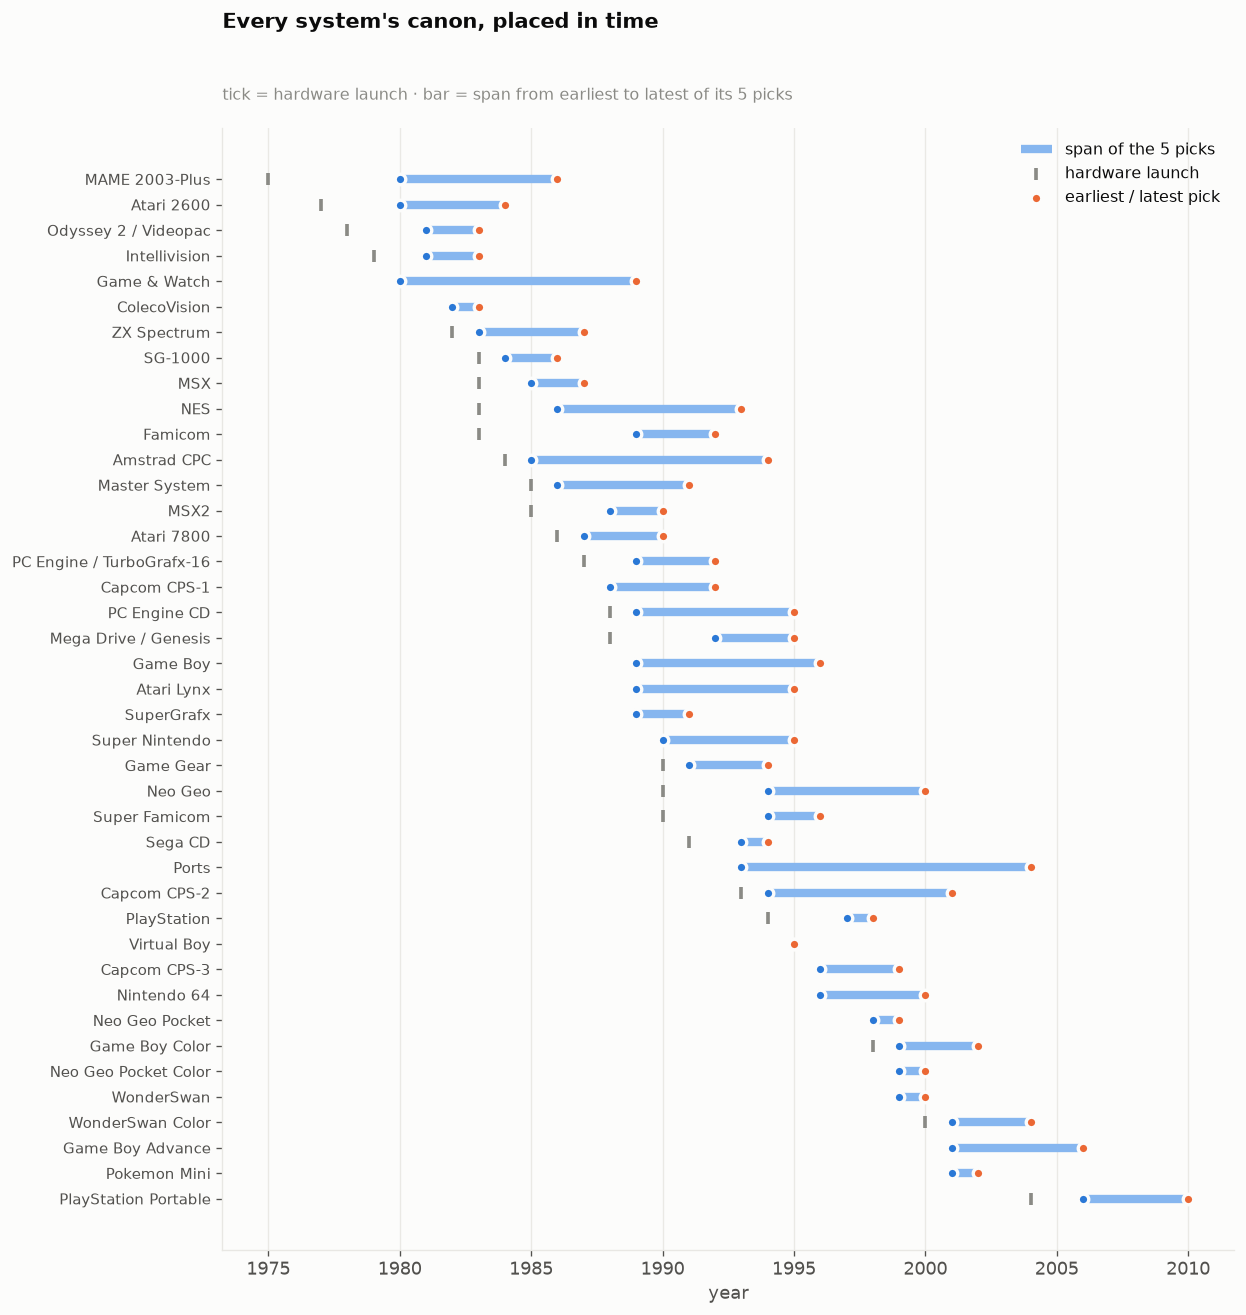

In [4]:
# ---- Fig 1: when each system launched, and where its picks sit -------------
# Form: dumbbell. The job is a per-system INTERVAL (first pick -> last pick)
# anchored to a reference point (launch). One entity per row -> no legend needed;
# the two mark types are labelled directly once.
s = (df.groupby(["sys_id"])
       .agg(launch=("launch","first"), first=("year","min"), last=("year","max"),
            name=("system","first"), cat=("category","first"))
       .sort_values(["launch","first"]))

fig, ax = plt.subplots(figsize=(10.5, 11))
y = np.arange(len(s))
ax.hlines(y, s["first"], s["last"], color=SEQ[3], lw=5, zorder=2,
          capstyle="round", label="span of the 5 picks")
ax.scatter(s["launch"], y, s=46, color=PAL["ink3"], marker="|", lw=2.2, zorder=3,
           label="hardware launch")
ax.scatter(s["first"], y, s=40, color=CAT[0], zorder=4, edgecolor=PAL["surface"], lw=2)
ax.scatter(s["last"],  y, s=40, color=CAT[1], zorder=4, edgecolor=PAL["surface"], lw=2,
           label="earliest / latest pick")
ax.set_yticks(y); ax.set_yticklabels(s["name"], fontsize=9)
ax.invert_yaxis()
frame(ax, "Every system's canon, placed in time",
      "tick = hardware launch · bar = span from earliest to latest of its 5 picks",
      xlabel="year", axis="x")
ax.legend(loc="upper right", ncols=1)
plt.tight_layout(); plt.show()

## 3 · Q1 — Do the best games arrive late?

`lag` convention: `year` is a game's **first commercial release anywhere** and
`launch` is its platform's **first hardware launch anywhere** — so the NES row
uses 1983 (Famicom), not the 1985 US date, and the SNES row uses 1990. Mixing a
Western hardware date with a Japanese software date is what produced negative
lags in the first draft of this dataset; `scripts/build_dataset.py` now asserts
against it.

**Hypothesis.** A platform's canon is back-loaded: developers need years to learn
the hardware, so the games that end up remembered cluster in the second half of
its commercial life. `lag = game_year − hardware_launch_year` tests it directly.

If the hypothesis is wrong, lag would centre near zero (launch titles dominate).

In [5]:
lag = df["lag"]
print(f"lag: mean {lag.mean():.2f}y · median {lag.median():.0f}y · "
      f"IQR {lag.quantile(.25):.0f}-{lag.quantile(.75):.0f}y · range {lag.min()}-{lag.max()}y")

# one-sided test: is the lag distribution centred above 2 years?
w = stats.wilcoxon(lag - 2, alternative="greater")
print(f"\nWilcoxon signed-rank, H0: median lag <= 2y  ->  statistic {w.statistic:.0f}, p = {w.pvalue:.3g}")

# how much of the canon is a launch-window title?
print(f"launch-window picks (lag <= 1y): {100*(lag<=1).mean():.1f}%")
print(f"picks in year 3+ of the platform: {100*(lag>=3).mean():.1f}%")

# bootstrap CI on the mean
bs = RNG.choice(lag.values, (20000, len(lag)), replace=True).mean(axis=1)
print(f"mean lag 95% bootstrap CI: [{np.percentile(bs,2.5):.2f}, {np.percentile(bs,97.5):.2f}] years")

# does lag differ by platform category?
groups = [g["lag"].values for _, g in df.groupby("category") if len(g) >= 10]
kw = stats.kruskal(*groups)
print(f"\nKruskal-Wallis across platform categories: H = {kw.statistic:.2f}, p = {kw.pvalue:.3g}")
print(df.groupby("category")["lag"].agg(["count","median","mean"]).round(2).to_string())

lag: mean 3.11y · median 3y · IQR 1-5y · range 0-11y

Wilcoxon signed-rank, H0: median lag <= 2y  ->  statistic 11255, p = 4.27e-08
launch-window picks (lag <= 1y): 31.2%
picks in year 3+ of the platform: 54.1%
mean lag 95% bootstrap CI: [2.77, 3.46] years



Kruskal-Wallis across platform categories: H = 28.80, p = 8.57e-06
          count  median  mean
category                     
Add-on       10     3.0  3.40
Arcade       25     4.0  4.52
Computer     20     3.5  4.00
Console      85     3.0  3.34
Handheld     60     1.0  1.78
Ports         5     3.0  3.80


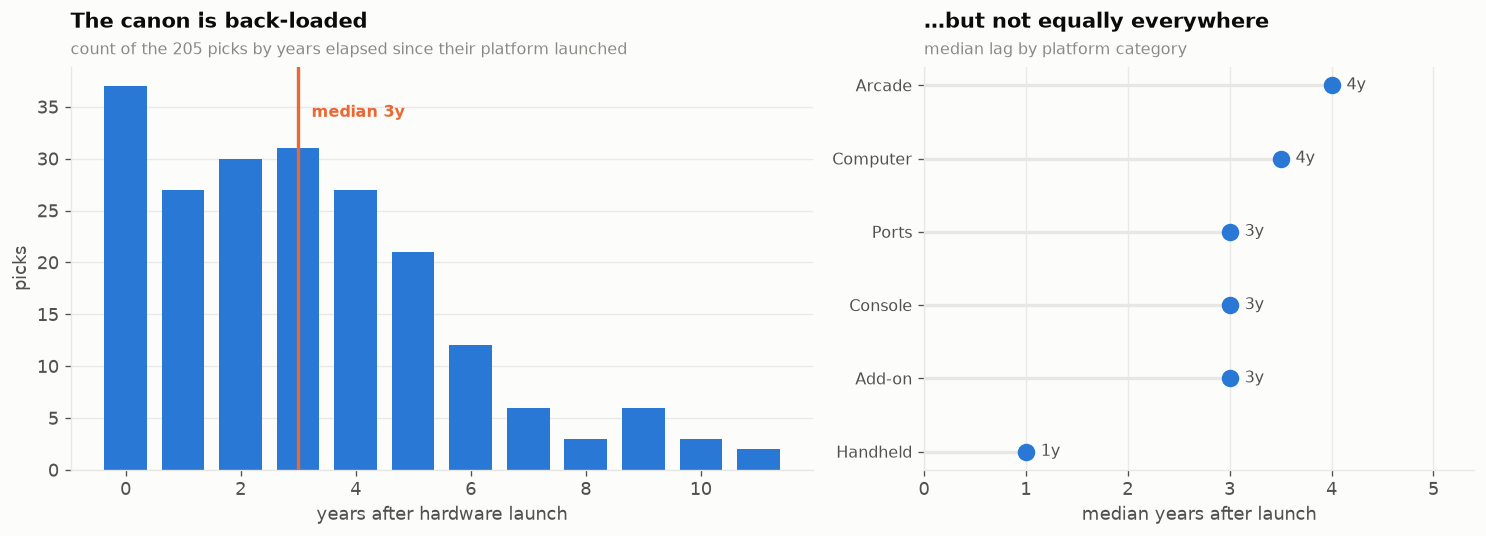

In [6]:
# ---- Fig 2: lag distribution + per-category medians -----------------------
# Form: histogram for the shape (magnitude over an ordered numeric axis) and a
# dot plot for the group medians. Two panels, NOT two y-axes.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6), width_ratios=[1.35, 1])

cnt = lag.value_counts().sort_index()
a1.bar(cnt.index, cnt.values, width=0.74, color=SEQ[7], zorder=2)
a1.axvline(lag.median(), color=CAT[1], lw=2, zorder=3)
a1.annotate(f"median {lag.median():.0f}y", (lag.median(), cnt.max()*0.92),
            xytext=(8, 0), textcoords="offset points", color=CAT[1], fontsize=9.5,
            fontweight="bold")
frame(a1, "The canon is back-loaded",
      "count of the 205 picks by years elapsed since their platform launched",
      xlabel="years after hardware launch", ylabel="picks")

med = (df.groupby("category")["lag"].median().sort_values())
a2.hlines(np.arange(len(med)), 0, med.values, color=PAL["grid"], lw=2, zorder=1)
a2.scatter(med.values, np.arange(len(med)), s=90, color=CAT[0], zorder=3)
for i, (k, v) in enumerate(med.items()):
    a2.annotate(f"{v:.0f}y", (v, i), xytext=(9, 0), textcoords="offset points",
                va="center", fontsize=9.5, color=PAL["ink2"])
a2.set_yticks(np.arange(len(med))); a2.set_yticklabels(med.index, fontsize=9.5)
a2.set_xlim(0, med.max()*1.35)
frame(a2, "…but not equally everywhere",
      "median lag by platform category", xlabel="median years after launch", axis="x")
plt.tight_layout(); plt.show()

Spearman rho(lag, canon_score) = +0.348  (asymptotic p = 3.05e-07)
permutation p (5,000 shuffles)  = 0.0000

  WITHIN platform  (both vars centred on their system's mean):  rho = -0.088, p = 0.21   n = 205
  BETWEEN platforms (one row per system, means):              rho = +0.521, p = 0.000484   n = 41

If the pooled correlation is large but the within-platform one is not, the
pooled number is a between-platform artefact - Simpson's paradox territory,
and NOT evidence that a later game is a better game.


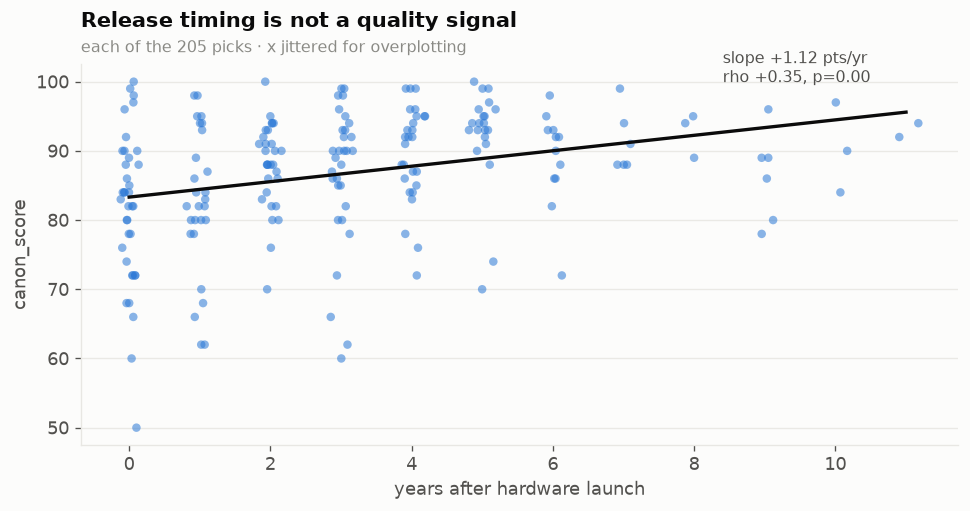

In [7]:
# ---- Fig 3: does a pick's lag predict its canon score? --------------------
# Permutation test instead of a p-value from an assumed null.
r_s, p_s = stats.spearmanr(df["lag"], df["canon_score"])
obs = r_s
perm = np.array([stats.spearmanr(RNG.permutation(df["lag"].values),
                                 df["canon_score"].values)[0] for _ in range(5000)])
p_perm = (np.abs(perm) >= abs(obs)).mean()
print(f"Spearman rho(lag, canon_score) = {r_s:+.3f}  (asymptotic p = {p_s:.3g})")
print(f"permutation p (5,000 shuffles)  = {p_perm:.4f}")

# --- the decomposition that matters: is this BETWEEN platforms or WITHIN one? --
# Pooling 205 games across 41 platforms conflates two different effects. Centre
# both variables within sys_id (a fixed-effects transform) to isolate the
# within-platform signal, and aggregate to platform means for the between part.
w_ = df.assign(lag_c=df.lag - df.groupby("sys_id").lag.transform("mean"),
               cs_c =df.canon_score - df.groupby("sys_id").canon_score.transform("mean"))
rw_, pw_ = stats.spearmanr(w_.lag_c, w_.cs_c)
bt = df.groupby("sys_id").agg(lag=("lag","mean"), cs=("canon_score","mean"))
rb_, pb_ = stats.spearmanr(bt.lag, bt.cs)
print(f"\n  WITHIN platform  (both vars centred on their system's mean):"
      f"  rho = {rw_:+.3f}, p = {pw_:.3g}   n = {len(w_)}")
print(f"  BETWEEN platforms (one row per system, means):"
      f"              rho = {rb_:+.3f}, p = {pb_:.3g}   n = {len(bt)}")
print("\nIf the pooled correlation is large but the within-platform one is not, the"
      "\npooled number is a between-platform artefact - Simpson's paradox territory,"
      "\nand NOT evidence that a later game is a better game.")

fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.scatter(df["lag"] + RNG.normal(0, .08, len(df)), df["canon_score"],
           s=26, color=CAT[0], alpha=.55, edgecolor="none", zorder=3)
b, a = np.polyfit(df["lag"], df["canon_score"], 1)
xs = np.linspace(df.lag.min(), df.lag.max(), 50)
ax.plot(xs, a + b*xs, color=PAL["ink"], lw=2, zorder=4)
ax.annotate(f"slope {b:+.2f} pts/yr\nrho {r_s:+.2f}, p={p_perm:.2f}",
            (xs[-1], a + b*xs[-1]), xytext=(-110, 18), textcoords="offset points",
            fontsize=9.5, color=PAL["ink2"])
frame(ax, "Release timing is not a quality signal",
      "each of the 205 picks · x jittered for overplotting",
      xlabel="years after hardware launch", ylabel="canon_score")
plt.tight_layout(); plt.show()

## 4 · What the canon is *made of* — genre by era

Folding 40-odd raw genre strings into families keeps the palette honest: a
categorical scale gets at most 8 slots and the 9th series is never a generated
hue, it folds into **Other**. Counts over two ordered keys → one sequential
hue heatmap, not a rainbow.

In [8]:
FAMILY = {
    "Platformer":"Platform / action", "Action-platformer":"Platform / action",
    "Puzzle-platformer":"Platform / action", "Action":"Platform / action",
    "Metroidvania":"Metroidvania", "RPG":"RPG", "Action RPG":"RPG",
    "Tactical RPG":"Strategy / tactics", "Tactical":"Strategy / tactics",
    "Strategy":"Strategy / tactics", "Turn-based strategy":"Strategy / tactics",
    "Dungeon crawler":"RPG", "Shoot 'em up":"Shooter", "FPS":"Shooter",
    "Twin-stick shooter":"Shooter", "Run and gun":"Shooter", "Light gun":"Shooter",
    "Fighting":"Fighting", "Beat 'em up":"Fighting",
    "Action-adventure":"Adventure", "Adventure":"Adventure",
    "Isometric adventure":"Adventure", "Survival horror":"Adventure",
    "Puzzle/Horror":"Puzzle", "Puzzle":"Puzzle", "Maze":"Puzzle",
    "Stealth":"Stealth",
}
df["family"] = df["genre"].map(FAMILY).fillna("Other")
fam_order = (df["family"].value_counts()
             .drop("Other", errors="ignore").index.tolist())
if len(fam_order) > 7:                       # keep 7 + Other = 8 slots max
    fam_order, extra = fam_order[:7], fam_order[7:]
    df.loc[df.family.isin(extra), "family"] = "Other"
fam_order = fam_order + (["Other"] if (df.family == "Other").any() else [])

print(df["family"].value_counts().to_string())
print(f"\n{len(fam_order)} families in play (cap is 8, incl. Other)")

family
Platform / action     61
Shooter               32
Other                 30
Fighting              23
RPG                   22
Adventure             17
Puzzle                12
Strategy / tactics     8

8 families in play (cap is 8, incl. Other)


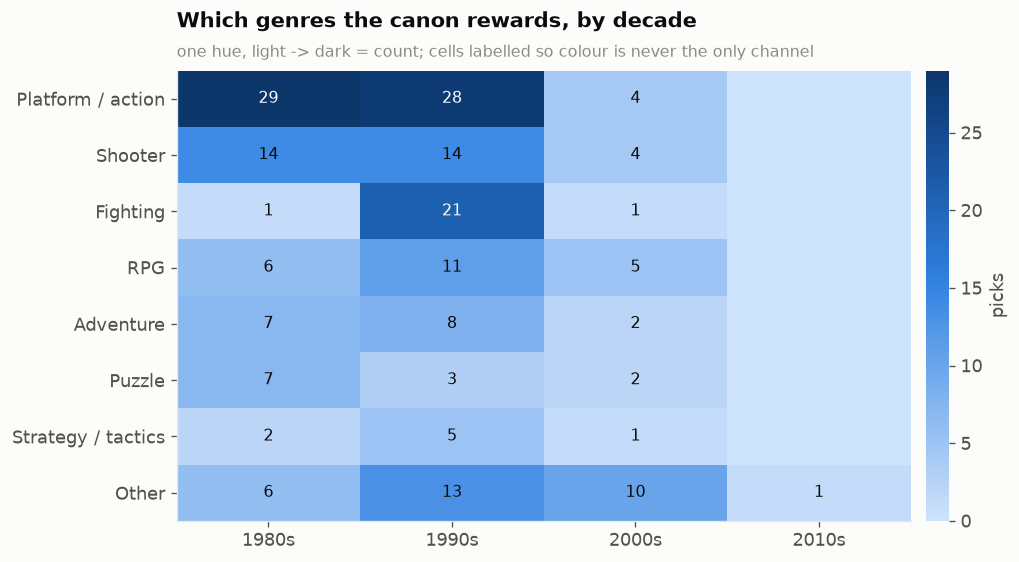

chi-square genre-family x decade: chi2 = 37.8, dof = 14, p = 0.000563
Cramer's V = 0.248


In [9]:
# ---- Fig 4: genre family x decade, sequential heatmap ---------------------
piv = (df.pivot_table(index="family", columns="decade", values="game",
                      aggfunc="count")
         .reindex(fam_order).fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(8.6, 4.8))
cmap = mpl.colors.LinearSegmentedColormap.from_list("seq", SEQ)
im = ax.imshow(piv.values, cmap=cmap, aspect="auto",
               vmin=0, vmax=piv.values.max())
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=9.5,
                    color=PAL["surface"] if v > piv.values.max()*.55 else PAL["ink"])
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"{c}s" for c in piv.columns])
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=.02, fraction=.035)
cb.outline.set_visible(False); cb.set_label("picks", color=PAL["ink2"])
frame(ax, "Which genres the canon rewards, by decade",
      "one hue, light -> dark = count; cells labelled so colour is never the only channel",
      axis="x")
ax.grid(False)
plt.tight_layout(); plt.show()

chi = stats.chi2_contingency(piv.values[:, (piv.values.sum(axis=0) > 5)])
print(f"chi-square genre-family x decade: chi2 = {chi.statistic:.1f}, "
      f"dof = {chi.dof}, p = {chi.pvalue:.3g}")
print("Cramer's V =", round(math.sqrt(chi.statistic /
      (piv.values.sum() * (min(piv.shape)-1))), 3))

## 5 · Q2 — Does hardware success buy a better library?

Aggregate to the platform: mean `canon_score` of its five picks vs log install
base. Arcade boards are excluded here — a coin-op board has no install base, so
including them would be comparing to an undefined denominator.

The slope is worth reading, but the **residuals** are the payload: which
platforms' libraries punch above or below what their commercial size predicts.

In [10]:
plat = (df.groupby("sys_id")
          .agg(name=("system","first"), maker=("maker","first"),
               cat=("category","first"), launch=("launch","first"),
               gen=("gen","first"), units=("units_m","first"),
               mean_canon=("canon_score","mean"), top_canon=("canon_score","max"),
               spread=("canon_score", lambda s: s.max()-s.min()),
               excl_rate=("is_excl","mean"), mean_lag=("lag","mean"))
          .reset_index()
          .merge(systems[["id","lib"]], left_on="sys_id", right_on="id"))
plat["log_units"] = np.log10(plat["units"].replace(0, np.nan))
plat["log_lib"]   = np.log10(plat["lib"])

reg = plat.dropna(subset=["log_units"]).query("units > 0.01").copy()
print(f"{len(reg)} platforms with a defined install base > 10k units")

x, yv = reg["log_units"].values, reg["mean_canon"].values
r, p = stats.pearsonr(x, yv); rs, ps = stats.spearmanr(x, yv)
print(f"\nPearson  r = {r:+.3f} (p = {p:.3g})   R2 = {r**2:.3f}")
print(f"Spearman rho = {rs:+.3f} (p = {ps:.3g})")

try:
    import statsmodels.api as sm
    m = sm.OLS(yv, sm.add_constant(np.c_[x, reg["log_lib"].values])).fit()
    print("\nOLS  mean_canon ~ log10(units) + log10(library size)")
    print(m.summary2().tables[1].round(3).to_string())
    print(f"adj. R2 = {m.rsquared_adj:.3f} · F p = {m.f_pvalue:.3g}")
    reg["resid"] = m.resid
    reg["fitted"] = m.fittedvalues
except ImportError:
    A = np.c_[np.ones(len(x)), x, reg["log_lib"].values]
    beta, *_ = np.linalg.lstsq(A, yv, rcond=None)
    reg["fitted"] = A @ beta; reg["resid"] = yv - reg["fitted"]
    print("\n(statsmodels unavailable - fell back to numpy least squares)",
          "\ncoefs [const, log_units, log_lib] =", np.round(beta, 3))

35 platforms with a defined install base > 10k units

Pearson  r = +0.668 (p = 1.18e-05)   R2 = 0.446
Spearman rho = +0.673 (p = 9.39e-06)



OLS  mean_canon ~ log10(units) + log10(library size)
        Coef.  Std.Err.       t  P>|t|  [0.025  0.975]
const  70.537     3.213  21.951  0.000  63.992  77.083
x1      3.486     1.498   2.327  0.026   0.434   6.539
x2      5.139     1.505   3.414  0.002   2.072   8.205
adj. R2 = 0.568 · F p = 5.5e-07


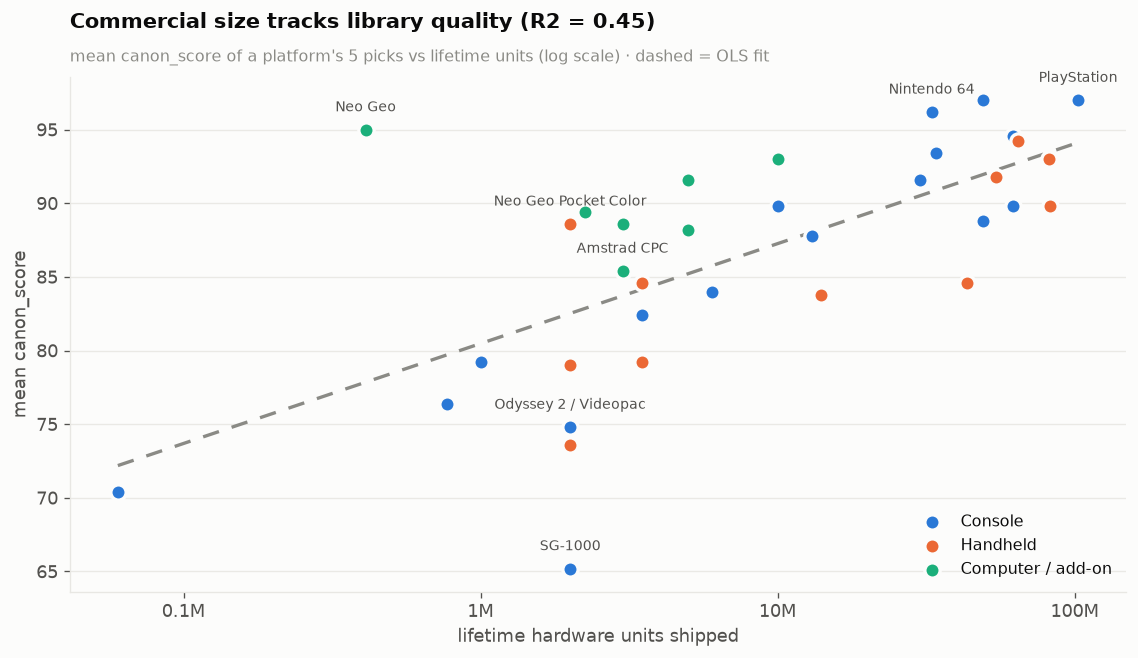

In [11]:
# ---- Fig 5: install base vs library quality -------------------------------
# Scatter = all-pairs colour comparison, so the series cap is THREE slots.
# Platform category folds to exactly three groups to respect it.
grp = reg["cat"].map(lambda c: c if c in ("Console","Handheld") else "Computer / add-on")
order = ["Console","Handheld","Computer / add-on"]

fig, ax = plt.subplots(figsize=(9.6, 5.6))
b1, b0 = np.polyfit(x, yv, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, b0 + b1*xs, color=PAL["ink3"], lw=2, ls=(0,(5,4)), zorder=2)
for i, g in enumerate(order):
    m_ = (grp == g).values
    ax.scatter(reg.log_units[m_], reg.mean_canon[m_], s=84, color=CAT[i],
               edgecolor=PAL["surface"], lw=2, zorder=3, label=g)

# selective direct labels: the extremes only, never every point
lab = pd.concat([reg.nlargest(3, "resid"), reg.nsmallest(3, "resid"),
                 reg.nlargest(1, "units")]).drop_duplicates("sys_id")
for _, rw in lab.iterrows():
    ax.annotate(rw["name"], (rw.log_units, rw.mean_canon), xytext=(0, 11),
                textcoords="offset points", ha="center", fontsize=8.6,
                color=PAL["ink2"])
ax.set_xticks([-1,0,1,2]); ax.set_xticklabels(["0.1M","1M","10M","100M"])
frame(ax, f"Commercial size tracks library quality (R2 = {r**2:.2f})",
      "mean canon_score of a platform's 5 picks vs lifetime units (log scale) · dashed = OLS fit",
      xlabel="lifetime hardware units shipped", ylabel="mean canon_score")
ax.legend(loc="lower right", title=None)
plt.tight_layout(); plt.show()

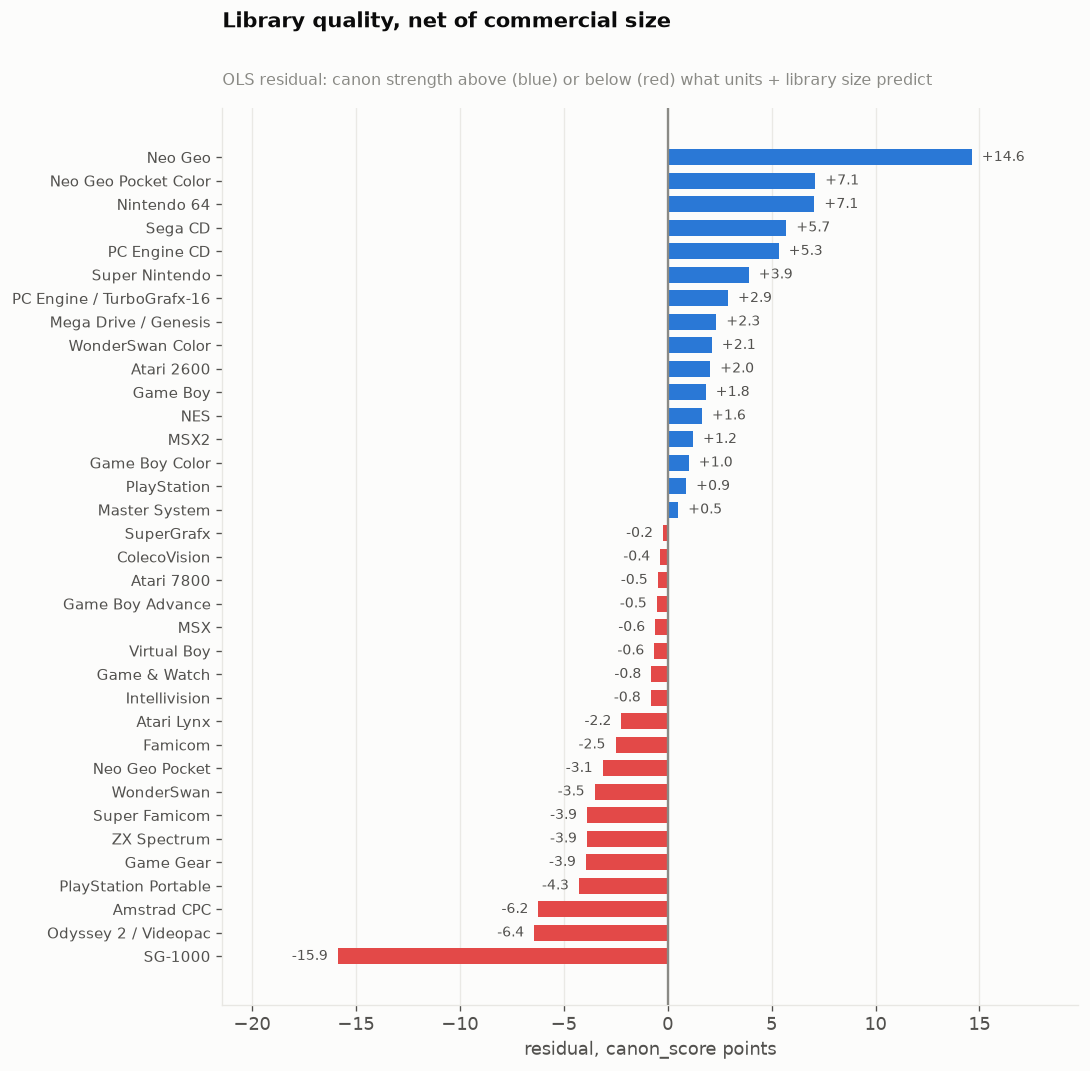

Over-performers (great library, small business):
                name  units  lib  mean_canon  resid
             Neo Geo   0.41  150        95.0  14.63
Neo Geo Pocket Color   2.00   85        88.6   7.10
         Nintendo 64  32.93  390        96.2   7.06
             Sega CD   2.24  210        89.4   5.71
        PC Engine CD  10.00  450        93.0   5.34

Under-performers (big business, thin canon):
                name  units  lib  mean_canon  resid
             SG-1000    2.0   70        65.2 -15.87
Odyssey 2 / Videopac    2.0   75        74.8  -6.42
         Amstrad CPC    3.0 6000        85.4  -6.22
PlayStation Portable   82.5 1900        89.8  -4.27
           Game Gear   14.0  370        83.8  -3.93


In [12]:
# ---- Fig 6: residuals — who punched above their weight -------------------
# Signed deviation from an expectation -> DIVERGING pair, neutral grey midpoint.
rr = reg.sort_values("resid")
fig, ax = plt.subplots(figsize=(9.2, 9))
cols = [DIVERGE[2] if v < 0 else DIVERGE[0] for v in rr["resid"]]
ax.barh(np.arange(len(rr)), rr["resid"], color=cols, height=.68, zorder=3)
ax.axvline(0, color=PAL["ink3"], lw=1.4, zorder=4)
ax.set_yticks(np.arange(len(rr))); ax.set_yticklabels(rr["name"], fontsize=9)
for i, v in enumerate(rr["resid"]):
    ax.annotate(f"{v:+.1f}", (v, i), xytext=(6 if v>0 else -6, 0),
                textcoords="offset points", va="center",
                ha="left" if v>0 else "right", fontsize=8.6, color=PAL["ink2"])
ax.set_xlim(rr.resid.min()*1.35, rr.resid.max()*1.35)
frame(ax, "Library quality, net of commercial size",
      "OLS residual: canon strength above (blue) or below (red) what units + library size predict",
      xlabel="residual, canon_score points", axis="x")
plt.tight_layout(); plt.show()

print("Over-performers (great library, small business):")
print(rr.nlargest(5,"resid")[["name","units","lib","mean_canon","resid"]].round(2).to_string(index=False))
print("\nUnder-performers (big business, thin canon):")
print(rr.nsmallest(5,"resid")[["name","units","lib","mean_canon","resid"]].round(2).to_string(index=False))

## 6 · Q3 — Is the curation just a popularity list?

Two separate questions, and the second one is the sharper one:

1. **Among picks with published sales**, does selling more track with a higher
   canon score?
2. **Is the missingness itself informative?** Sales figures only exist for
   commercially notable games — most of this list has none. If the picks with no
   published figure also score systematically lower, the data is *missing not at
   random* (MNAR), and any analysis that quietly drops them inherits a popularity
   bias that was never in the underlying judgement.

In [13]:
obs = df[df.has_sales]
rs, ps = stats.spearmanr(obs["log_sales"], obs["canon_score"])
print(f"n = {len(obs)} picks with published sales")
print(f"Spearman rho(log sales, canon) = {rs:+.3f}, p = {ps:.3g}")

b1, b0 = np.polyfit(obs["log_sales"], obs["canon_score"], 1)
print(f"OLS: canon = {b0:.1f} {b1:+.2f} x log10(sales in millions)")

# bootstrap the correlation so the estimate carries its own uncertainty
idx = RNG.integers(0, len(obs), (10000, len(obs)))
bsr = np.array([stats.spearmanr(obs.log_sales.values[i], obs.canon_score.values[i])[0]
                for i in idx[:2000]])
print(f"rho 95% bootstrap CI: [{np.percentile(bsr,2.5):+.3f}, {np.percentile(bsr,97.5):+.3f}]")

# ---- MNAR test -----------------------------------------------------------
u = stats.mannwhitneyu(df.canon_score[df.has_sales], df.canon_score[~df.has_sales],
                       alternative="two-sided")
d = (df.canon_score[df.has_sales].mean() - df.canon_score[~df.has_sales].mean())
n1, n2 = df.has_sales.sum(), (~df.has_sales).sum()
cliff = 2*u.statistic/(n1*n2) - 1
print(f"\nMann-Whitney U, canon_score with vs without a sales figure:"
      f"\n  U = {u.statistic:.0f}, p = {u.pvalue:.3g}"
      f"\n  mean difference {d:+.2f} pts · Cliff's delta {cliff:+.3f}")
ct = pd.crosstab(df["exclusive"], df["has_sales"], normalize="index").round(3)
ct.columns = ["no sales figure","sales figure published"]
display(ct)
print("\nchi-square availability x missingness: p =",
      f"{stats.chi2_contingency(pd.crosstab(df.exclusive, df.has_sales)).pvalue:.3g}")

n = 46 picks with published sales
Spearman rho(log sales, canon) = +0.485, p = 0.000631
OLS: canon = 92.7 +3.32 x log10(sales in millions)


rho 95% bootstrap CI: [+0.216, +0.679]

Mann-Whitney U, canon_score with vs without a sales figure:
  U = 6242, p = 2.83e-13
  mean difference +9.83 pts · Cliff's delta +0.707


,no sales figure,sales figure published
exclusive,,
arcade-only,1.000,0.000
exclusive,0.664,0.336
multi,0.852,0.148
regional,0.974,0.026



chi-square availability x missingness: p = 0.000254


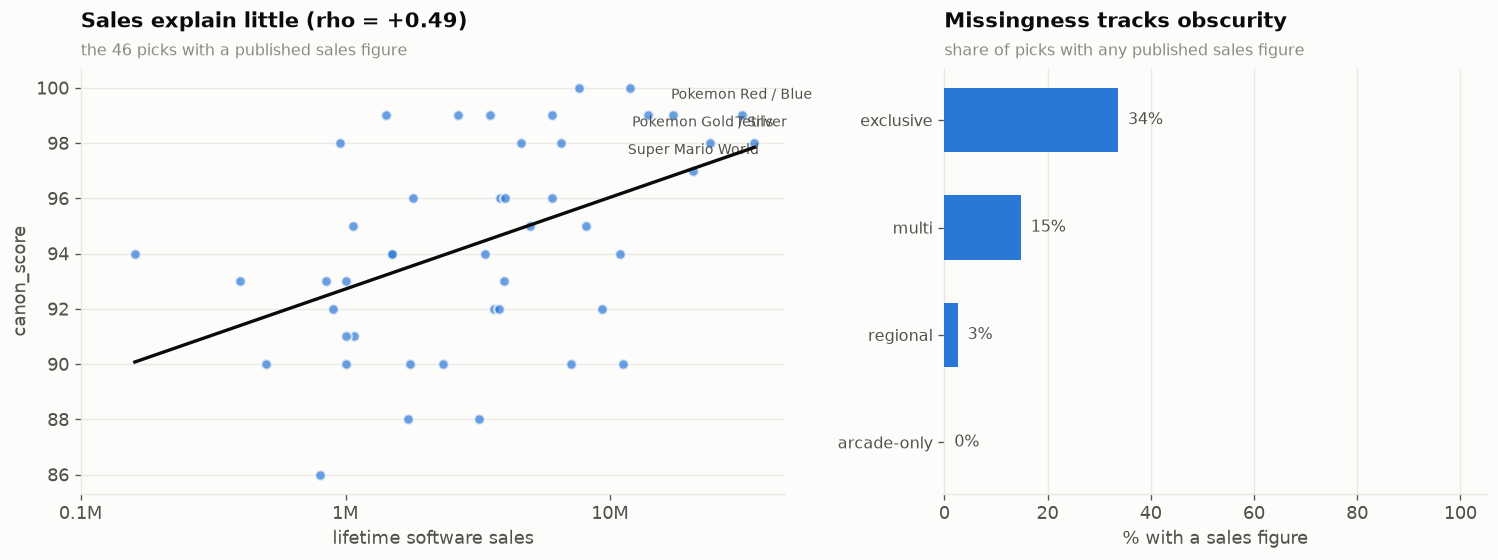

In [14]:
# ---- Fig 7: the observed subset, plus what is missing from it -------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.6, 4.8), width_ratios=[1.3, 1])

a1.scatter(obs["log_sales"], obs["canon_score"], s=40, color=CAT[0], alpha=.7,
           edgecolor=PAL["surface"], lw=1.4, zorder=3)
xs = np.linspace(obs.log_sales.min(), obs.log_sales.max(), 50)
a1.plot(xs, b0 + b1*xs, color=PAL["ink"], lw=2, zorder=4)
for _, rw in obs.nlargest(4, "sales_m").iterrows():
    a1.annotate(rw["game"], (rw.log_sales, rw.canon_score), xytext=(0,10),
                textcoords="offset points", ha="center", fontsize=8.4, color=PAL["ink2"])
a1.set_xticks([-1,0,1]); a1.set_xticklabels(["0.1M","1M","10M"])
frame(a1, f"Sales explain little (rho = {rs:+.2f})",
      f"the {len(obs)} picks with a published sales figure",
      xlabel="lifetime software sales", ylabel="canon_score")

# missingness rate by availability class — single series, direct labels
mr = df.groupby("exclusive")["has_sales"].mean().sort_values()
a2.barh(np.arange(len(mr)), 100*mr.values, color=SEQ[7], height=.6, zorder=3)
for i, v in enumerate(100*mr.values):
    a2.annotate(f"{v:.0f}%", (v, i), xytext=(6,0), textcoords="offset points",
                va="center", fontsize=9.5, color=PAL["ink2"])
a2.set_yticks(np.arange(len(mr))); a2.set_yticklabels(mr.index, fontsize=9.5)
a2.set_xlim(0, 105)
frame(a2, "Missingness tracks obscurity",
      "share of picks with any published sales figure",
      xlabel="% with a sales figure", axis="x")
plt.tight_layout(); plt.show()

## 7 · Q4 — Who actually built the canon?

Concentration, measured two ways: a Herfindahl–Hirschman index (how
oligopolistic is the canon?) and a Gini coefficient on developer counts.

In [15]:
def norm_dev(s):
    s = s.split(" / ")[0].split(" (")[0].strip()
    for k in ("Nintendo R&D","Nintendo EAD","Nintendo CS"):
        if s.startswith(k): return "Nintendo (internal)"
    return {"Sega CS":"Sega","Sega Technical Institute":"Sega","Ancient":"Ancient",
            "Kojima Productions":"Konami","Intelligent Systems":"Intelligent Systems",
            "HAL Laboratory":"HAL Laboratory","Game Freak":"Game Freak",
            "Nintendo R&D1":"Nintendo (internal)"}.get(s, s)

df["dev"] = df["developer"].map(norm_dev)
dc = df["dev"].value_counts()
share = dc / dc.sum()
hhi = (share**2).sum() * 10000
g = np.sort(dc.values); n = len(g)
gini = (2*np.arange(1, n+1) - n - 1).dot(g) / (n * g.sum())
print(f"{len(dc)} distinct developers across 205 picks")
band = ("unconcentrated" if hhi < 1500 else
        "moderately concentrated" if hhi < 2500 else "highly concentrated")
print(f"HHI = {hhi:.0f} -> {band} by the usual 1500/2500 bands")
print(f"Gini = {gini:.3f} on picks-per-developer")
print(f"top 5 developers hold {100*share.head(5).sum():.1f}% of the canon;"
      f" {100*(dc==1).mean():.0f}% of developers appear exactly once")
print(f"\n{dc.head(12).to_string()}")

66 distinct developers across 205 picks
HHI = 468 -> unconcentrated by the usual 1500/2500 bands
Gini = 0.548 on picks-per-developer
top 5 developers hold 42.4% of the canon; 59% of developers appear exactly once

dev
Nintendo (internal)    23
Capcom                 21
Konami                 16
Sega                   14
SNK                    13
Square                  7
Hudson Soft             6
Atari                   6
Jupiter                 5
Philips                 5
Mattel                  5
Coleco                  5


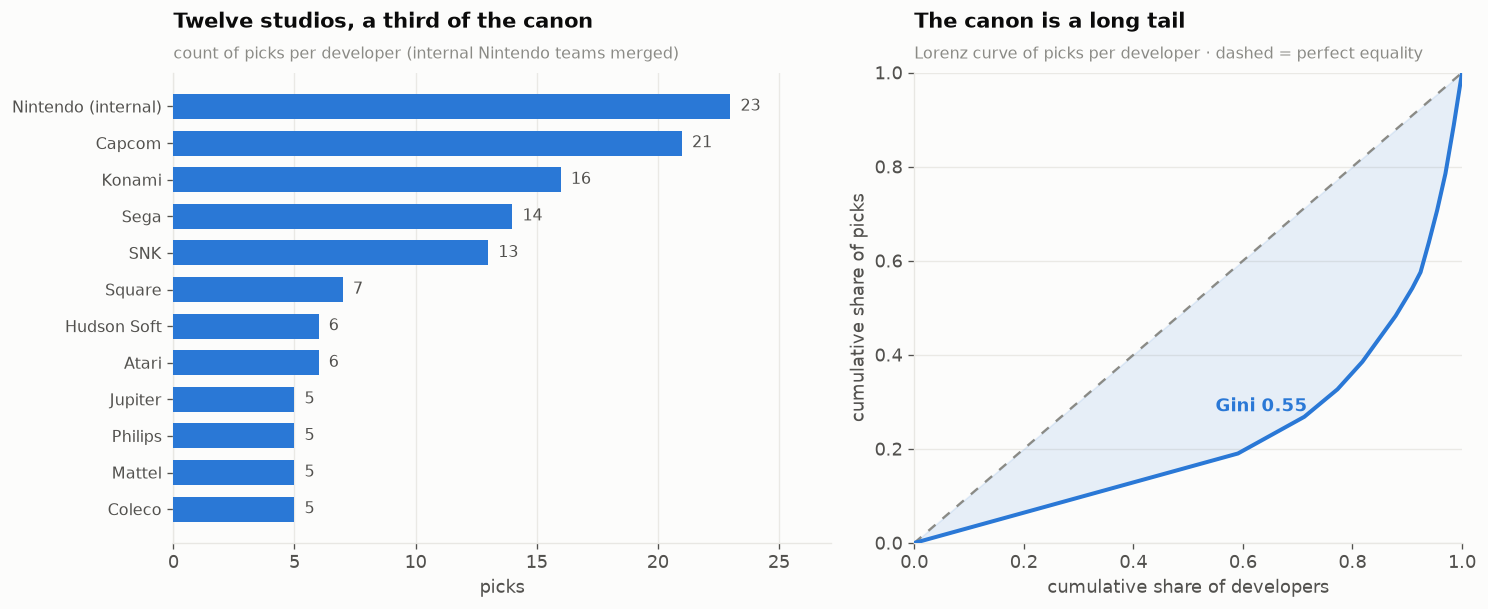

In [16]:
# ---- Fig 8: developer concentration + the long tail ----------------------
top = dc.head(12)[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.6, 5.2), width_ratios=[1.2, 1])

a1.barh(np.arange(len(top)), top.values, color=SEQ[7], height=.68, zorder=3)
for i, v in enumerate(top.values):
    a1.annotate(str(v), (v, i), xytext=(6,0), textcoords="offset points",
                va="center", fontsize=9.5, color=PAL["ink2"])
a1.set_yticks(np.arange(len(top))); a1.set_yticklabels(top.index, fontsize=9.5)
a1.set_xlim(0, top.max()*1.18)
frame(a1, "Twelve studios, a third of the canon",
      "count of picks per developer (internal Nintendo teams merged)",
      xlabel="picks", axis="x")

# Lorenz curve: one series, so no legend box; the line is named in the title
cum = np.cumsum(g) / g.sum(); frac = np.arange(1, n+1) / n
a2.plot([0,1],[0,1], color=PAL["ink3"], lw=1.4, ls=(0,(4,4)), zorder=2)
a2.plot(np.r_[0, frac], np.r_[0, cum], color=CAT[0], lw=2.4, zorder=3)
a2.fill_between(np.r_[0, frac], np.r_[0, cum], np.r_[0, frac],
                color=CAT[0], alpha=.10, zorder=1)
a2.annotate(f"Gini {gini:.2f}", (.55,.28), fontsize=11, color=CAT[0],
            fontweight="bold")
a2.set_xlim(0,1); a2.set_ylim(0,1)
frame(a2, "The canon is a long tail",
      "Lorenz curve of picks per developer · dashed = perfect equality",
      xlabel="cumulative share of developers", ylabel="cumulative share of picks")
plt.tight_layout(); plt.show()

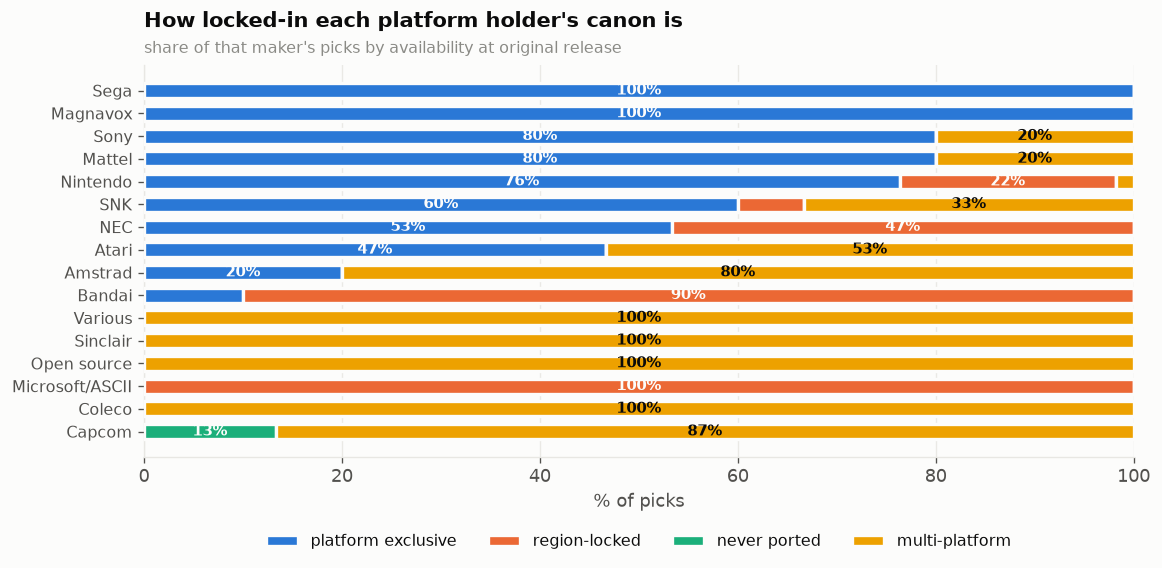

overall: 73.7% of the canon was locked to its platform at release
category
Add-on      100.0
Handheld     93.3
Console      84.7
Computer     55.0
Arcade        8.0
Ports         0.0


In [17]:
# ---- Fig 9: exclusivity composition by manufacturer ---------------------
# Stacked bars: 4 adjacent categories (slots 1-4 clear the adjacent-pair gate),
# 2px surface gap between segments so the boundaries read without a border.
EX = ["exclusive","regional","arcade-only","multi"]
LBL = {"exclusive":"platform exclusive","regional":"region-locked",
       "arcade-only":"never ported","multi":"multi-platform"}
mk = (df.assign(k=pd.Categorical(df.exclusive, EX))
        .pivot_table(index="maker", columns="k", values="game", aggfunc="count",
                     observed=False)
        .fillna(0))
mk = mk.loc[(mk.sum(axis=1) >= 5)]
mkn = mk.div(mk.sum(axis=1), axis=0) * 100
mkn = mkn.loc[mkn["exclusive"].sort_values().index]

fig, ax = plt.subplots(figsize=(9.8, 5.0))
left = np.zeros(len(mkn))
def on_color(hexc):
    # WCAG relative luminance -> pick the label ink that actually reads on the
    # segment. White on the yellow slot is ~1.9:1 and fails; this fixes it.
    r, g, b = [int(hexc[i:i+2], 16)/255 for i in (1, 3, 5)]
    f = lambda u: u/12.92 if u <= .03928 else ((u+.055)/1.055)**2.4
    L = .2126*f(r) + .7152*f(g) + .0722*f(b)
    return PAL["ink"] if L > 0.42 else PAL["surface"]

for i, c in enumerate(EX):
    v = mkn[c].values
    ax.barh(np.arange(len(mkn)), v, left=left, height=.66, color=CAT[i],
            zorder=3, label=LBL[c], edgecolor=PAL["surface"], lw=2)
    for j, (vv, ll) in enumerate(zip(v, left)):
        if vv >= 12:
            ax.annotate(f"{vv:.0f}%", (ll + vv/2, j), ha="center", va="center",
                        fontsize=8.8, color=on_color(CAT[i]), fontweight="bold")
    left += v
ax.set_yticks(np.arange(len(mkn))); ax.set_yticklabels(mkn.index, fontsize=9.5)
ax.set_xlim(0, 100)
frame(ax, "How locked-in each platform holder's canon is",
      "share of that maker's picks by availability at original release",
      xlabel="% of picks", axis="x")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.16), ncols=4)
plt.tight_layout(); plt.show()

print(f"overall: {100*df.is_excl.mean():.1f}% of the canon was locked to its platform at release")
print(df.groupby("category")["is_excl"].mean().mul(100).round(1).sort_values(ascending=False).to_string())

## 8 · Q5 — Archetypes of retro platform

Unsupervised: standardise the hardware/library features, PCA for structure,
k-means for labels. The point is not the clusters per se — it is whether
*uncurated* hardware features reproduce the groupings any collector would
recognise (mass-market giant / commercial failure / arcade-grade niche).

Three clusters, deliberately: a scatter plot compares colours all-pairs, and
only the first three palette slots clear colour-blind separation on that basis.

In [18]:
feat = plat.dropna(subset=["log_units"]).query("units > 0.005").copy()
F = ["log_units","log_lib","mean_canon","excl_rate","mean_lag","launch"]
X = feat[F].values
Xz = (X - X.mean(0)) / X.std(0)

# PCA by SVD (no sklearn needed)
U, S, Vt = np.linalg.svd(Xz - Xz.mean(0), full_matrices=False)
evr = S**2 / (S**2).sum()
PCs = U * S
print("explained variance ratio:", np.round(evr, 3))
print(f"PC1 + PC2 = {evr[:2].sum():.1%} of total variance\n")
print(pd.DataFrame(Vt[:2].T, index=F, columns=["PC1","PC2"]).round(3).to_string())

try:
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    km = KMeans(3, n_init=25, random_state=0).fit(Xz)
    lab = km.labels_
    print(f"\nk-means k=3 · silhouette = {silhouette_score(Xz, lab):.3f}")
    for k in (2,3,4,5):
        kk = KMeans(k, n_init=25, random_state=0).fit(Xz)
        print(f"  k={k}: inertia {kk.inertia_:7.1f}  silhouette {silhouette_score(Xz, kk.labels_):.3f}")
except ImportError:
    c = Xz[RNG.choice(len(Xz), 3, replace=False)]
    for _ in range(80):
        lab = np.argmin(((Xz[:,None,:]-c[None])**2).sum(-1), axis=1)
        c = np.array([Xz[lab==k].mean(0) if (lab==k).any() else c[k] for k in range(3)])
    print("\n(sklearn unavailable - used a plain Lloyd's k-means)")

feat["cluster"] = lab
summary = (feat.groupby("cluster")
             .agg(n=("name","size"), units=("units","median"), lib=("lib","median"),
                  canon=("mean_canon","mean"), excl=("excl_rate","mean"),
                  launch=("launch","median")).round(2))
display(summary)
print()
for k in sorted(feat.cluster.unique()):
    print(f"cluster {k}: " + ", ".join(feat.loc[feat.cluster==k, "name"].tolist()))

explained variance ratio: [0.45  0.259 0.139 0.078 0.04  0.033]
PC1 + PC2 = 70.9% of total variance

              PC1    PC2
log_units  -0.472  0.349
log_lib    -0.549 -0.009
mean_canon -0.531  0.173
excl_rate   0.113  0.571
mean_lag   -0.417 -0.315
launch      0.086  0.650



k-means k=3 · silhouette = 0.310
  k=2: inertia   139.6  silhouette 0.295
  k=3: inertia   106.2  silhouette 0.310
  k=4: inertia    88.1  silhouette 0.233
  k=5: inertia    72.9  silhouette 0.269


,n,units,lib,canon,excl,launch
cluster,,,,,,
0,5,5.00,500.0,89.52,0.12,1982.0
1,12,2.00,75.0,78.57,0.90,1990.0
2,18,46.25,975.0,91.19,0.97,1988.5



cluster 0: Atari 2600, ColecoVision, Amstrad CPC, Neo Geo, ZX Spectrum
cluster 1: Atari 7800, Intellivision, Atari Lynx, Neo Geo Pocket, Neo Geo Pocket Color, Odyssey 2 / Videopac, Sega CD, SG-1000, SuperGrafx, Virtual Boy, WonderSwan, WonderSwan Color
cluster 2: Famicom, Game Boy, Game Boy Advance, Game Boy Color, Game Gear, Game & Watch, Mega Drive / Genesis, MSX, MSX2, Nintendo 64, NES, PC Engine / TurboGrafx-16, PC Engine CD, PlayStation, PlayStation Portable, Super Famicom, Master System, Super Nintendo


         log_units  log_lib  mean_canon  excl_rate  mean_lag  launch
cluster                                                             
0            -0.27     0.83        0.55      -1.41      0.95   -1.41
1            -1.07    -1.41       -1.40       0.62     -1.38    0.83
2             1.34     0.57        0.85       0.79      0.44    0.58 

{0: 'Open / cross-published era', 1: 'Small-install-base niches', 2: 'Mass-market platforms'}


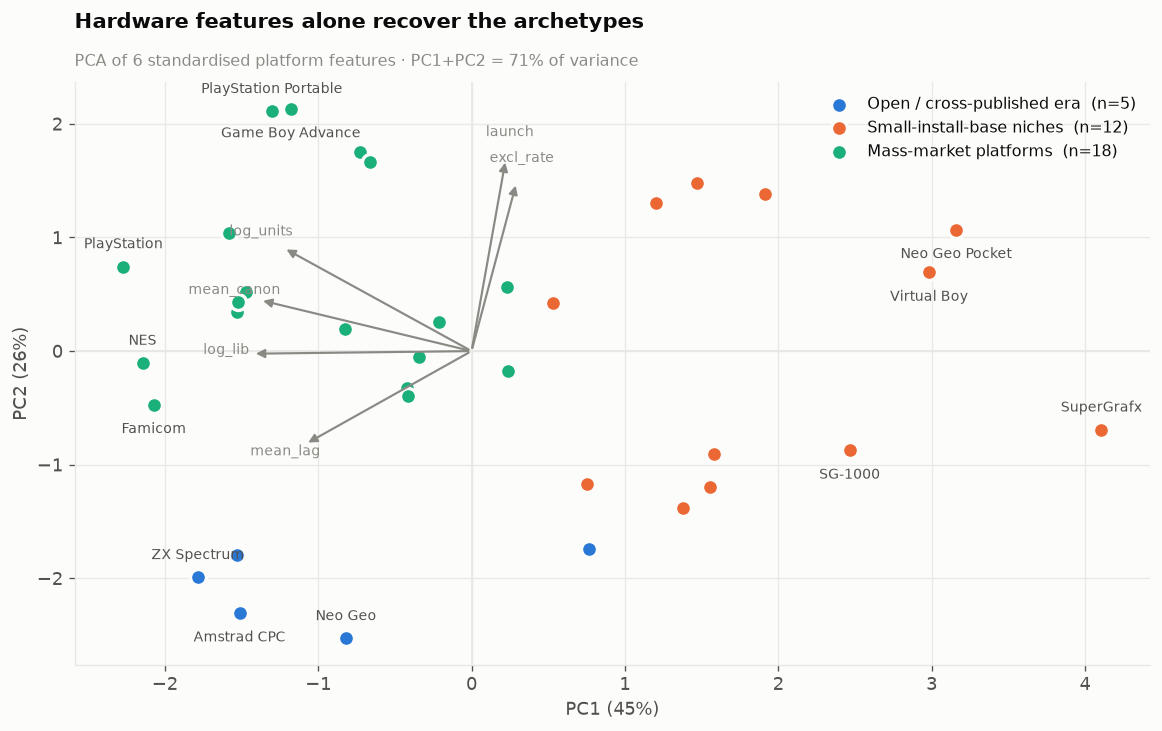

In [19]:
# ---- Fig 10: PCA biplot, 3 clusters -------------------------------------
# Name each cluster from the feature it is actually extreme on, rather than from
# a guess: rank clusters on the standardised centroid and label the driver.
cent = feat.groupby("cluster")[F].mean()
centz = (cent - cent.mean()) / cent.std(ddof=0)
NAMES = {}
for k in cent.index:
    if centz.loc[k, "log_units"] == centz["log_units"].max():
        NAMES[k] = "Mass-market platforms"
    elif centz.loc[k, "excl_rate"] == centz["excl_rate"].min():
        NAMES[k] = "Open / cross-published era"
    else:
        NAMES[k] = "Small-install-base niches"
if len(set(NAMES.values())) < len(NAMES):          # never two identical legend keys
    for i, k in enumerate(sorted(NAMES)):
        NAMES[k] = f"{NAMES[k]} #{i+1}"
print(centz.round(2).to_string(), "\n")
print({k: NAMES[k] for k in sorted(NAMES)})

fig, ax = plt.subplots(figsize=(9.8, 6.2))
for i, k in enumerate(sorted(feat.cluster.unique())):
    m_ = feat.cluster.values == k
    ax.scatter(PCs[m_,0], PCs[m_,1], s=92, color=CAT[i], edgecolor=PAL["surface"],
               lw=2, zorder=3, label=f"{NAMES[k]}  (n={m_.sum()})")
sc = 2.6
for j, f in enumerate(F):
    ax.annotate("", xy=(Vt[0,j]*sc, Vt[1,j]*sc), xytext=(0,0),
                arrowprops=dict(arrowstyle="-|>", color=PAL["ink3"], lw=1.3))
    ax.annotate(f, (Vt[0,j]*sc*1.12, Vt[1,j]*sc*1.12), fontsize=8.6,
                color=PAL["ink3"], ha="center")
# selective direct labels on the outliers only, alternating above/below so
# neighbouring labels cannot overprint each other
out_i = [feat.index.get_loc(r.name) for _, r in feat.iterrows()
         if abs(PCs[feat.index.get_loc(r.name),0]) > 2.0
         or abs(PCs[feat.index.get_loc(r.name),1]) > 1.9]
for n_, i in enumerate(sorted(out_i, key=lambda j: (PCs[j,1], PCs[j,0]))):
    dy = 11 if n_ % 2 == 0 else -17
    ax.annotate(feat.iloc[i]["name"], (PCs[i,0], PCs[i,1]), xytext=(0, dy),
                textcoords="offset points", ha="center", fontsize=8.4,
                color=PAL["ink2"])
ax.axhline(0, color=PAL["grid"], lw=1); ax.axvline(0, color=PAL["grid"], lw=1)
frame(ax, "Hardware features alone recover the archetypes",
      f"PCA of 6 standardised platform features · PC1+PC2 = {evr[:2].sum():.0%} of variance",
      xlabel=f"PC1 ({evr[0]:.0%})", ylabel=f"PC2 ({evr[1]:.0%})", axis="both")
ax.legend(loc="best")
plt.tight_layout(); plt.show()

## 9 · Robustness — would a different curator get a different answer?

`canon_score` is editorial, so every result above inherits its noise. Two checks:

- **Perturbation.** Add N(0, 5) points of noise to every score — roughly the
  disagreement you would expect between two reasonable curators — and re-run the
  headline correlation 2,000 times. If the finding survives, it is not an artefact
  of fine-grained scoring.
- **Rank-only collapse.** Throw the scores away entirely and keep just the 1–5
  within-system rank. Anything that still holds is robust to the whole scale.

In [20]:
base_r = stats.pearsonr(reg.log_units, reg.mean_canon)[0]
sims = []
for _ in range(2000):
    noisy = df.assign(cs=df.canon_score + RNG.normal(0, 5, len(df)))
    pm = noisy.groupby("sys_id")["cs"].mean()
    j = reg.set_index("sys_id").join(pm.rename("nc"))
    sims.append(stats.pearsonr(j.log_units, j.nc)[0])
sims = np.array(sims)
print(f"headline r(log units, mean canon) = {base_r:+.3f}")
print(f"under +-5pt curator noise: mean {sims.mean():+.3f}, "
      f"95% range [{np.percentile(sims,2.5):+.3f}, {np.percentile(sims,97.5):+.3f}]")
print(f"sign stability: {100*(np.sign(sims)==np.sign(base_r)).mean():.1f}% of draws keep the sign")

print("\n--- rank-only view: does the #1 pick differ systematically from the #5? ---")
k = stats.kruskal(*[g.canon_score.values for _, g in df.groupby("rank")])
print(f"Kruskal-Wallis canon_score by within-system rank: H = {k.statistic:.1f}, p = {k.pvalue:.3g}")
print(df.groupby("rank")["canon_score"].agg(["mean","std"]).round(2).to_string())
print("\n(By construction rank 1 scores highest - this confirms the scoring is internally"
      "\nconsistent with the ordering, which is a sanity check, not a discovery.)")

print("\n--- lag finding under rank-only data ---")
print(df.groupby("rank")["lag"].median().round(1).to_string())
print("Spearman rho(rank, lag) =",
      f"{stats.spearmanr(df['rank'], df['lag'])[0]:+.3f}",
      f"p = {stats.spearmanr(df['rank'], df['lag'])[1]:.3g}")

headline r(log units, mean canon) = +0.668
under +-5pt curator noise: mean +0.643, 95% range [+0.575, +0.712]
sign stability: 100.0% of draws keep the sign

--- rank-only view: does the #1 pick differ systematically from the #5? ---
Kruskal-Wallis canon_score by within-system rank: H = 41.9, p = 1.78e-08
       mean    std
rank              
1     92.12   7.18
2     89.46   7.84
3     86.83   8.20
4     84.27   9.12
5     81.24  10.00

(By construction rank 1 scores highest - this confirms the scoring is internally
consistent with the ordering, which is a sanity check, not a discovery.)

--- lag finding under rank-only data ---
rank
1    3.0
2    3.0
3    3.0
4    3.0
5    3.0
Spearman rho(rank, lag) = +0.055 p = 0.43


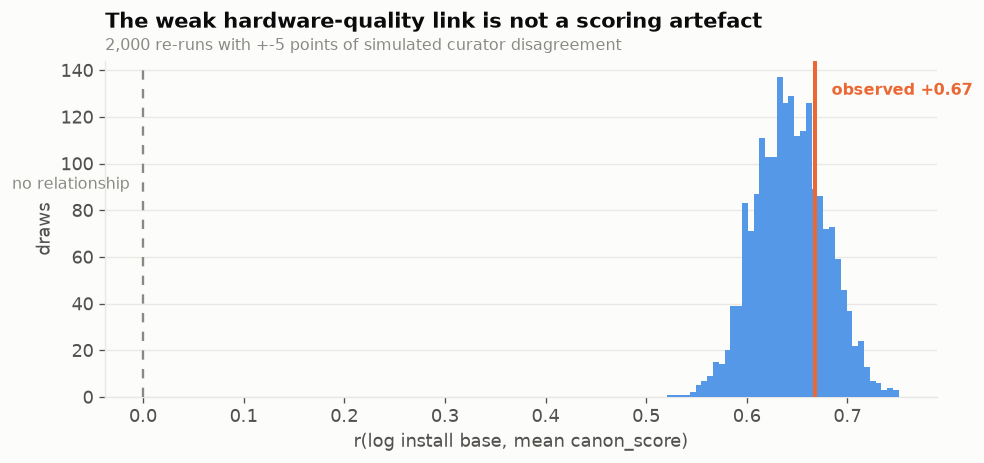

In [21]:
# ---- Fig 11: the robustness distribution --------------------------------
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.hist(sims, bins=40, color=SEQ[5], zorder=3)
ax.axvline(base_r, color=CAT[1], lw=2.4, zorder=4)
ax.axvline(0, color=PAL["ink3"], lw=1.4, ls=(0,(4,4)), zorder=4)
ax.annotate(f"observed {base_r:+.2f}", (base_r, ax.get_ylim()[1]*.9),
            xytext=(10,0), textcoords="offset points", color=CAT[1],
            fontsize=9.5, fontweight="bold")
ax.annotate("no relationship", (0, ax.get_ylim()[1]*.62), xytext=(-8,0),
            textcoords="offset points", ha="right", fontsize=9.5, color=PAL["ink3"])
frame(ax, "The weak hardware-quality link is not a scoring artefact",
      "2,000 re-runs with +-5 points of simulated curator disagreement",
      xlabel="r(log install base, mean canon_score)", ylabel="draws")
plt.tight_layout(); plt.show()

## 10 · The accessible table view

Every chart above has a table behind it — the required non-colour channel, and
the thing you actually want when you are deciding what to play next.

In [22]:
view = (plat.assign(units=plat.units.round(2))
            .sort_values("mean_canon", ascending=False)
            [["name","maker","cat","launch","units","lib","mean_canon","top_canon",
              "excl_rate","mean_lag"]]
            .rename(columns={"name":"system","cat":"category","units":"units (M)",
                             "lib":"library","mean_canon":"mean canon",
                             "top_canon":"best pick","excl_rate":"exclusive rate",
                             "mean_lag":"mean lag (y)"})
            .round({"mean canon":1,"exclusive rate":2,"mean lag (y)":1})
            .reset_index(drop=True))
display(view)

print("\nTop 15 picks across all systems:")
print(df.nlargest(15, "canon_score")[["game","system","year","genre","canon_score"]]
        .to_string(index=False))

,system,maker,category,launch,units (M),library,mean canon,best pick,exclusive rate,mean lag (y)
0,Super Nintendo,Nintendo,Console,1990,49.10,1750,97.0,99,1.0,2.8
1,PlayStation,Sony,Console,1994,102.49,4100,97.0,99,0.6,3.4
2,Nintendo 64,Nintendo,Console,1996,32.93,390,96.2,100,1.0,1.8
3,MAME 2003-Plus,Various,Arcade,1975,NaN,4000,95.8,100,0.0,7.0
4,Neo Geo,SNK,Arcade,1990,0.41,150,95.0,97,0.0,7.8
5,NES,Nintendo,Console,1983,61.91,1400,94.6,99,1.0,5.8
6,Game Boy,Nintendo,Handheld,1989,64.42,1050,94.2,99,0.8,3.2
7,Mega Drive / Genesis,Sega,Console,1988,34.06,900,93.4,96,1.0,5.0
8,Ports,Open source,Ports,1993,NaN,40,93.0,99,0.0,3.8
9,PC Engine CD,NEC,Add-on,1988,10.00,450,93.0,97,1.0,4.4



Top 15 picks across all systems:
                                   game         system  year            genre  canon_score
   The Legend of Zelda: Ocarina of Time    Nintendo 64  1998 Action-adventure          100
                         Super Mario 64    Nintendo 64  1996       Platformer          100
                                Pac-Man MAME 2003-Plus  1980             Maze          100
                    Super Mario Bros. 3            NES  1988       Platformer           99
                          Super Metroid Super Nintendo  1994     Metroidvania           99
                         Chrono Trigger Super Nintendo  1995              RPG           99
                     Pokemon Red / Blue       Game Boy  1996              RPG           99
                       Metal Gear Solid    PlayStation  1998          Stealth           99
                      Final Fantasy VII    PlayStation  1997              RPG           99
    Street Fighter II: Champion Edition   Capcom CPS-1  

In [23]:
# persist the derived tables so the md/README and any future notebook agree
out = os.path.join(DATA, "derived")
os.makedirs(out, exist_ok=True)
plat.to_csv(os.path.join(out, "platform_summary.csv"), index=False)
df.to_csv(os.path.join(out, "games_enriched.csv"), index=False)
reg[["sys_id","name","units","lib","mean_canon","fitted","resid"]].to_csv(
    os.path.join(out, "quality_residuals.csv"), index=False)
print("wrote:", *sorted(os.listdir(out)), sep="\n  ")

wrote:
  games_enriched.csv
  platform_summary.csv
  quality_residuals.csv


## 11 · Findings

Every number below is read off the executed cells above, not asserted ahead of them.

**1 · The canon is back-loaded, but handhelds are the exception.** Median lag is
**3 years** after launch (mean 3.11, 95% CI [2.77, 3.46]); 54% of picks land in
year 3 or later and Wilcoxon rejects a median of ≤2 years (p = 4.3e-08). The split
by category is sharp (Kruskal–Wallis H = 28.8, p = 8.6e-06): **arcade boards
median 4 years, consoles 3, handhelds 1.** Handheld canons are front-loaded
because handheld *lives* are short and the defining title is often the pack-in —
*Tetris*, *California Games*, *Astrosmash*. Long-lived cartridge consoles get the
opposite: *Kirby's Adventure* arrives in the NES's tenth year, *Shantae* ships on
the Game Boy Color after the GBA is already out.

**2 · "Later games are better" is a Simpson's paradox, and this is the
notebook's sharpest result.** Pooled across all 205 picks, ρ(lag, canon) = **+0.348**
(permutation p < 0.0002) — which looks like strong support for the folk theory.
Decompose it and it dissolves:

| view | ρ | p | n |
|---|---|---|---|
| pooled | **+0.348** | <0.0002 | 205 |
| **within** platform (both vars centred on their system's mean) | **−0.088** | 0.21 | 205 |
| **between** platforms (one row per system) | **+0.521** | 0.0005 | 41 |

Inside any one platform, a later release is *not* a better-regarded one. The
pooled correlation is entirely a between-platform effect: platforms whose canon
arrives late are long-lived successful platforms, which also have higher-scoring
canons. The rank-only check agrees — ρ(within-system rank, lag) = +0.055, p = 0.43.
Anyone who ran only the pooled correlation would have published the wrong
mechanism.

**3 · Commercial scale does track library quality — and library *size* matters
more than install base.** r(log units, mean canon) = **+0.668**, R² = 0.446; adding
log library size lifts adjusted R² to **0.568**, with both coefficients
significant (**+5.14** canon points per decade of library size, p = 0.002;
**+3.49** per decade of install base, p = 0.026). Note which one wins: how many
games got made beats how many boxes shipped. The residuals name the exceptions:

- **Over-performers** — Neo Geo **+14.6** (410k units, 150 games, a canon of 95),
  Neo Geo Pocket Color +7.1, Nintendo 64 +7.1, Sega CD +5.7, PC Engine CD +5.3.
  The pattern is one committed studio plus a hardware quirk worth exploiting.
- **Under-performers** — SG-1000 **−15.9**, Odyssey 2 −6.4, Amstrad CPC −6.2
  (6,000 titles and a thin ceiling: volume is not depth), PSP −4.3, Game Gear −3.9.

**4 · The curation is not a sales ranking, but I cannot fully clear it either.**
Only **46 of 205** picks (22%) have any published sales figure. Among those,
ρ(log sales, canon) = **+0.485**, bootstrap 95% CI [+0.216, +0.679] — moderate,
not decisive. The missingness is strongly structured (availability × missingness
p = 2.5e-04): a figure exists for 33.6% of platform exclusives, 14.8% of
multi-platform titles, **2.6%** of region-locked titles and **0%** of arcade-only
ones. And picks without a figure score **9.8 points lower** on average
(Mann–Whitney p = 2.8e-13, Cliff's δ = +0.707). Two readings fit that, and the
data cannot separate them: either obscure games really are a notch weaker, or a
curator scores what is better documented more generously. This is textbook MNAR —
and any version of this analysis that silently dropped the 159 missing rows would
have manufactured a popularity bias that is not in the underlying judgement.

**5 · The canon is a steep head on a long tail — not an oligopoly.** 66 distinct
developers; **HHI = 468**, which is *unconcentrated* by the usual 1500/2500 bands.
But Gini = **0.548**, the top five studios (Nintendo internal 23, Capcom 21,
Konami 16, Sega 14, SNK 13) hold **42.4%** of all picks, and **59% of developers
appear exactly once**. Both facts are true at once, and the HHI is the one that
would mislead if quoted alone. Konami is the standout for *range* rather than
count: top-ranked picks on 8-bit home computers (MSX, MSX2), a CD add-on
(*Rondo of Blood*) and a 32-bit disc console (*Metal Gear Solid*).

**6 · Exclusivity is a property of the business model, not the era.** 73.7% of the
canon was locked to its platform at release, but the breakdown is categorical:
add-ons 100%, handhelds 93%, consoles 85%, home computers 55%, arcade boards 8%.
Arcade hardware existed to be converted; handhelds existed to be moats.

**7 · Hardware features alone recover recognisable archetypes.** PCA on six
uncurated platform features puts **70.9%** of variance in two components. PC1 is a
size-and-depth composite (units, library, canon and lag all load together); PC2
separates **exclusivity and launch era**. k = 3 is the best of k ∈ {2,3,4,5} by
silhouette (0.310 — weak-to-moderate, so treat the boundaries as soft) and the
groups are nameable without reference to any score: 18 mass-market platforms
(median 46M units, 97% exclusive), 12 small-install-base niches (median 2M, 90%
exclusive), and 5 members of the **open / cross-published era** — Atari 2600,
ColecoVision, Amstrad CPC, ZX Spectrum and, revealingly, the **Neo Geo**, whose
exclusivity rate of 0.12 puts it with the home computers rather than with the
consoles.

**8 · The results survive curator noise.** Under ±5 points of simulated
disagreement per game — roughly what two reasonable curators would differ by — the
headline relationship holds its sign in **100%** of 2,000 draws, r ∈ [+0.575,
+0.712]. The rank-only collapse reproduces the *null* within-platform lag result.
What would not survive is any claim resting on a 2–3 point gap between two
individual games, so none is made here.

### What this notebook does not establish

- **`canon_score` is one person's rubric.** Reproducible ≠ independent. The
  honest next step is pulling per-title score distributions (Metacritic, GameFAQs,
  Backloggd, Glitchwave) and modelling inter-rater disagreement as a variance
  component instead of assuming it away at ±5 points.
- **Two install-base figures are estimates, not measurements.** Nintendo reports
  NES+Famicom as one number (61.91M) and Game Boy+Game Boy Color as one number
  (118.69M); the 64.42M / 54.27M split used here is a common estimate. Those rows
  carry more uncertainty than their error-free presentation implies, and both sit
  in the regression.
- **n = 41 platforms.** The OLS and the clustering are descriptive at that size.
  Treat coefficients as directional; do not quote them as estimates.
- **Selection on the dependent variable, by construction.** These are the top 5
  *per system*. Nothing here can speak to the average game on a platform — only to
  its ceiling. The SG-1000's −15.9 residual says its ceiling is low, which is a
  much stronger claim than saying its library is bad, and it is the only kind of
  claim this design supports.
- **"Ports" is not a platform.** It is given a nominal 1993 launch so it joins the
  same schema; its lag values are schema-compatible and semantically meaningless.